# NSL-KDD exploratory data analysis

This notebook checks the train/test class balance, attacks present only in KDDTest+, categorical cardinality, zero-variance features, and the range differences between byte counts and rate features. It uses the project loader so labels and feature columns follow the shared data contract. Run from the repository root.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'data.py').exists())
sys.path.insert(0, str(repo_root))
from src.data import CATEGORICAL_COLUMNS, get_numeric_columns, load_nsl_kdd
from src.data import _load_raw, DATA_DIR

sns.set_theme(style='whitegrid')
X_train, y_train_bin, y_train_cat, X_test, y_test_bin, y_test_cat = load_nsl_kdd()
train_raw = _load_raw(DATA_DIR / 'KDDTrain+.txt')
test_raw = _load_raw(DATA_DIR / 'KDDTest+.txt')
print(f'Train shape: {X_train.shape}; test shape: {X_test.shape}')
print(f'Categorical: {CATEGORICAL_COLUMNS}; numeric: {len(get_numeric_columns())}')

Loaded NSL-KDD:
  Train: 125,973 rows  |  Normal: 67,343  Attack: 58,630
  Test:  22,544 rows  |  Normal: 9,711  Attack: 12,833
  Dedupe Check: Train duplicate feature rows: 16, Test duplicates: 57, Exact overlap: 668
  Categories (train): {'normal': 67343, 'dos': 45927, 'probe': 11656, 'r2l': 995, 'u2r': 52}
  Categories (test):  {'normal': 9711, 'dos': 7460, 'r2l': 2885, 'probe': 2421, 'u2r': 67}


Train shape: (125973, 41); test shape: (22544, 41)
Categorical: ['protocol_type', 'service', 'flag']; numeric: 38


## Binary and five-class balance

The binary view is used for the paper reproduction. The five-class view exposes the strong imbalance among attack families, especially R2L and U2R.

,train,test
class,,
dos,45927,7460
normal,67343,9711
probe,11656,2421
r2l,995,2885
u2r,52,67


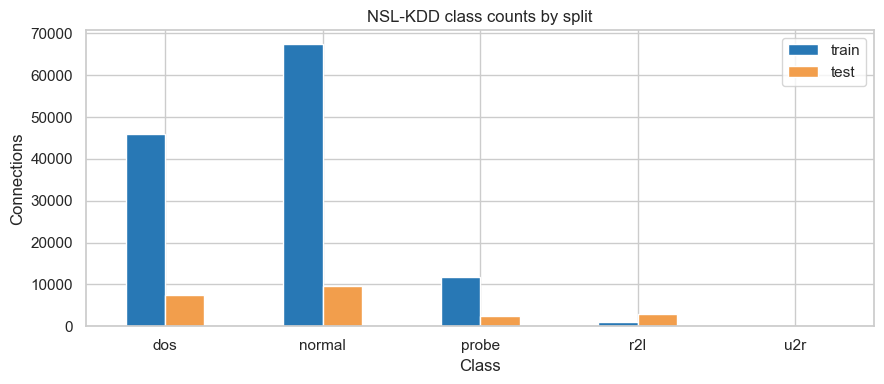

In [2]:
balance = pd.DataFrame({
    'train': y_train_cat.value_counts(),
    'test': y_test_cat.value_counts(),
}).fillna(0).astype(int).rename_axis('class')
display(balance)
balance.plot(kind='bar', figsize=(9, 4), color=['#2878B5', '#F29E4C'])
plt.title('NSL-KDD class counts by split')
plt.ylabel('Connections')
plt.xlabel('Class')
plt.xticks(rotation=0)
plt.tight_layout()

## Attack types present only in the test set

This identifies unseen attack names rather than only unseen rows. These attacks make KDDTest+ a harder generalization check.

In [3]:
train_attacks = set(train_raw['attack_type']) - {'normal'}
test_attacks = set(test_raw['attack_type']) - {'normal'}
test_only_attacks = sorted(test_attacks - train_attacks)
test_only_counts = (test_raw[test_raw['attack_type'].isin(test_only_attacks)]
                    ['attack_type'].value_counts().rename_axis('attack').to_frame('test_rows'))
print(f'Attack types in train: {len(train_attacks)}')
print(f'Attack types in test: {len(test_attacks)}')
print(f'Test-only attack types: {len(test_only_attacks)}')
display(test_only_counts)

Attack types in train: 22
Attack types in test: 37
Test-only attack types: 17


,test_rows
attack,
mscan,996
apache2,737
processtable,685
snmpguess,331
saint,319
mailbomb,293
snmpgetattack,178
httptunnel,133
named,17


## Categorical cardinality and constant features

Cardinality helps explain the increase in model input width after one-hot encoding. Zero-variance columns carry no information in the training set and are listed for review.

In [4]:
cardinality = X_train[CATEGORICAL_COLUMNS].nunique(dropna=False).sort_values(ascending=False)
display(cardinality.rename('unique_values').to_frame())

nunique = X_train.nunique(dropna=False)
zero_variance = nunique[nunique <= 1].index.tolist()
print(f"Zero-variance features in KDDTrain+: {zero_variance or 'None'}")
print(f'Number of zero-variance features: {len(zero_variance)}')

,unique_values
service,70
flag,11
protocol_type,3


Zero-variance features in KDDTrain+: ['num_outbound_cmds']
Number of zero-variance features: 1


## Feature scale ranges

Byte counts can be orders of magnitude larger than rate features. The summary below is computed on KDDTrain+ before scaling; it motivates fitting the numeric scaler on training data only.

,min,max,mean,std
src_bytes,0.0,1.379964e+09,45566.743000,5.870331e+06
dst_bytes,0.0,1.309937e+09,19779.114421,4.021269e+06
count,0.0,5.110000e+02,84.107555,1.145086e+02
srv_count,0.0,5.110000e+02,27.737888,7.263584e+01
serror_rate,0.0,1.000000e+00,0.284485,4.464556e-01
srv_serror_rate,0.0,1.000000e+00,0.282485,4.470225e-01
same_srv_rate,0.0,1.000000e+00,0.660928,4.396229e-01
diff_srv_rate,0.0,1.000000e+00,0.063053,1.803144e-01


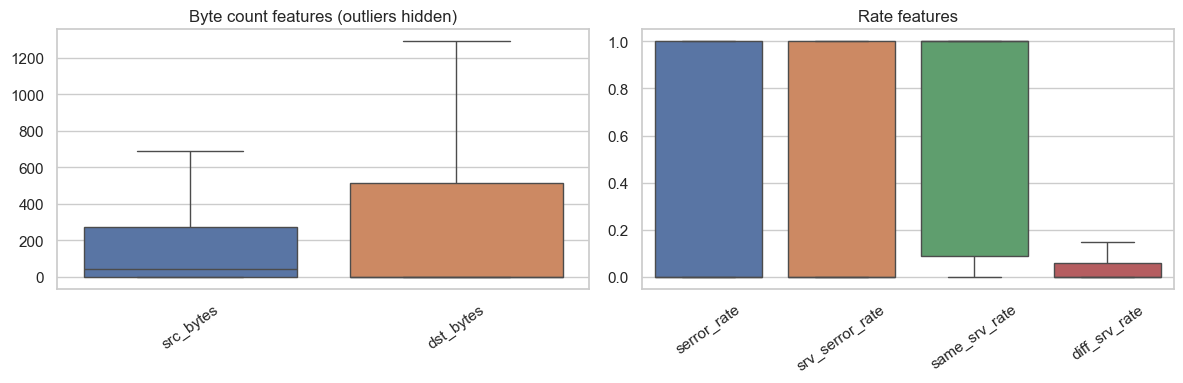

In [5]:
scale_features = ['src_bytes', 'dst_bytes', 'count', 'srv_count', 'serror_rate',
                  'srv_serror_rate', 'same_srv_rate', 'diff_srv_rate']
scale_summary = X_train[scale_features].describe().T[['min', 'max', 'mean', 'std']]
display(scale_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_train[['src_bytes', 'dst_bytes']], showfliers=False, ax=axes[0])
axes[0].set_title('Byte count features (outliers hidden)')
sns.boxplot(data=X_train[['serror_rate', 'srv_serror_rate', 'same_srv_rate', 'diff_srv_rate']],
            showfliers=False, ax=axes[1])
axes[1].set_title('Rate features')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()

## Takeaways

- The class counts and test-only attack names describe why accuracy on KDDTest+ is a demanding generalization measure.
- One-hot encoding expands the three categorical fields according to their train-set cardinality.
- Byte-count features have much wider raw ranges than rates, so numeric scaling is important for PCA and other distance-sensitive methods.
- Any learned encoder or scaler must be fit on KDDTrain+ only and then applied to KDDTest+.